What Relates to JAMB Scores? An Analysis of 5,000 Students

Dataset: Jamb result - 2024. Tools: Python, pandas, seaborn, matplotlib.

In [3]:
%pip install seaborn pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv(r"C:\Users\Hp\Documents\Student Performance project\jamb_exam_results.csv")

In [4]:
df.head()

,JAMB_Score,Study_Hours_Per_Week,Attendance_Rate,Teacher_Quality,Distance_To_School,School_Type,School_Location,Extra_Tutorials,Access_To_Learning_Materials,Parent_Involvement,IT_Knowledge,Student_ID,Age,Gender,Socioeconomic_Status,Parent_Education_Level,Assignments_Completed
0,192,22,78,4,12.4,Public,Urban,Yes,Yes,High,Medium,1,17,Male,Low,Tertiary,2
1,207,14,88,4,2.7,Public,Rural,No,Yes,High,High,2,15,Male,High,NaN,1
2,182,29,87,2,9.6,Public,Rural,Yes,Yes,High,Medium,3,20,Female,High,Tertiary,2
3,210,29,99,2,2.6,Public,Urban,No,Yes,Medium,High,4,22,Female,Medium,Tertiary,1
4,199,12,98,3,8.8,Public,Urban,No,Yes,Medium,Medium,5,22,Female,Medium,Tertiary,1


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   JAMB_Score                    5000 non-null   int64  
 1   Study_Hours_Per_Week          5000 non-null   int64  
 2   Attendance_Rate               5000 non-null   int64  
 3   Teacher_Quality               5000 non-null   int64  
 4   Distance_To_School            5000 non-null   float64
 5   School_Type                   5000 non-null   str    
 6   School_Location               5000 non-null   str    
 7   Extra_Tutorials               5000 non-null   str    
 8   Access_To_Learning_Materials  5000 non-null   str    
 9   Parent_Involvement            5000 non-null   str    
 10  IT_Knowledge                  5000 non-null   str    
 11  Student_ID                    5000 non-null   int64  
 12  Age                           5000 non-null   int64  
 13  Gender        

In [6]:
df.shape

(5000, 17)

In [7]:
df.isna().sum()

JAMB_Score                        0
Study_Hours_Per_Week              0
Attendance_Rate                   0
Teacher_Quality                   0
Distance_To_School                0
School_Type                       0
School_Location                   0
Extra_Tutorials                   0
Access_To_Learning_Materials      0
Parent_Involvement                0
IT_Knowledge                      0
Student_ID                        0
Age                               0
Gender                            0
Socioeconomic_Status              0
Parent_Education_Level          891
Assignments_Completed             0
dtype: int64

Parent Education Level has 891 null values out of 5000. Should i fill in the missing values or drop them? If i drop them, I would lose a good amount of my data. So i will fill the column with its mode.

In [8]:
#trying to find the most common education level
df['Parent_Education_Level'].value_counts()

Parent_Education_Level
Secondary    1556
Primary      1335
Tertiary     1218
Name: count, dtype: int64

In [9]:
#Secondary level is the most common with 1556 counts, so we fill it into those with null values
df['Parent_Education_Level'] = df['Parent_Education_Level'].fillna("Secondary")


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   JAMB_Score                    5000 non-null   int64  
 1   Study_Hours_Per_Week          5000 non-null   int64  
 2   Attendance_Rate               5000 non-null   int64  
 3   Teacher_Quality               5000 non-null   int64  
 4   Distance_To_School            5000 non-null   float64
 5   School_Type                   5000 non-null   str    
 6   School_Location               5000 non-null   str    
 7   Extra_Tutorials               5000 non-null   str    
 8   Access_To_Learning_Materials  5000 non-null   str    
 9   Parent_Involvement            5000 non-null   str    
 10  IT_Knowledge                  5000 non-null   str    
 11  Student_ID                    5000 non-null   int64  
 12  Age                           5000 non-null   int64  
 13  Gender        

In [11]:
df["JAMB_Score"].max()

np.int64(367)

In [12]:
df["JAMB_Score"].min()

np.int64(100)

In [13]:
df["JAMB_Score"].mean()

np.float64(174.0746)

In [14]:
df.describe()

,JAMB_Score,Study_Hours_Per_Week,Attendance_Rate,Teacher_Quality,Distance_To_School,Student_ID,Age,Assignments_Completed
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,174.074600,19.521200,84.235200,2.521400,10.005460,2500.500000,18.445800,1.804600
std,47.616477,9.634569,9.485688,0.985564,4.820221,1443.520003,2.301504,0.992076
min,100.000000,0.000000,50.000000,1.000000,0.000000,1.000000,15.000000,1.000000
25%,135.000000,13.000000,78.000000,2.000000,6.600000,1250.750000,16.000000,1.000000
50%,170.000000,19.000000,84.000000,2.000000,10.000000,2500.500000,18.000000,1.000000
75%,209.000000,26.000000,91.000000,3.000000,13.400000,3750.250000,20.000000,2.000000
max,367.000000,40.000000,100.000000,5.000000,20.000000,5000.000000,22.000000,5.000000


In [15]:
df.duplicated().sum()
df['Age'].describe()
df['Distance_To_School'].describe()

count    5000.000000
mean       10.005460
std         4.820221
min         0.000000
25%         6.600000
50%        10.000000
75%        13.400000
max        20.000000
Name: Distance_To_School, dtype: float64

np.float64(0.4200612209671164)

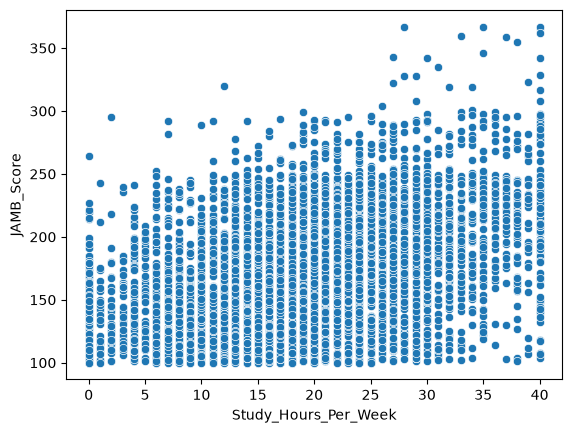

In [16]:
sns.scatterplot(data=df, x='Study_Hours_Per_Week', y='JAMB_Score')
df['Study_Hours_Per_Week'].corr(df['JAMB_Score'])

In [18]:
df['Study_Hours_Per_Week'].corr(df['JAMB_Score'])

np.float64(0.4200612209671164)

Question: Do students who study more score higher in JAMB?

Finding: Yes, moderately. The correlation between weekly study hours and JAMB score is 0.42, a moderate positive relationship. Study hours explain about 18% of the variation in scores, so other factors must also matter.

Caution: This shows the two go together, not that studying alone causes higher scores.

<Axes: xlabel='Extra_Tutorials', ylabel='JAMB_Score'>

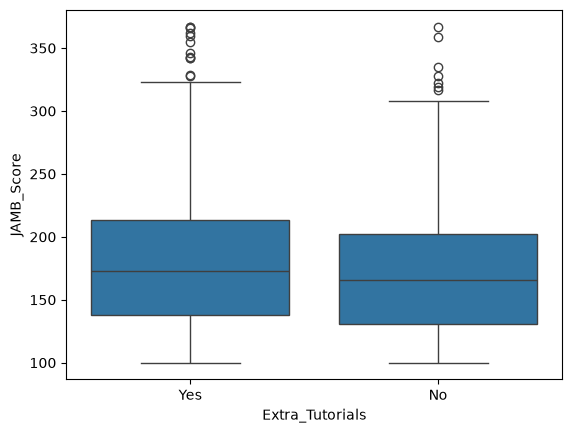

In [19]:
sns.boxplot(data=df, x='Extra_Tutorials', y='JAMB_Score')

In [20]:
df.groupby('Extra_Tutorials')['JAMB_Score'].agg(['mean', 'median', 'count'])

,mean,median,count
Extra_Tutorials,,,
No,170.566477,166.0,2279
Yes,177.012863,173.0,2721


Question: Do extra tutorials help JAMB scores?

Finding: Slightly. Students with extra tutorials averaged 177.0 vs 170.6 for those without, a gap of about 6.5 points out of 400. The difference is small, and the score ranges overlap heavily.

Comparison: Weekly study hours (correlation 0.42) had a stronger link to scores than extra tutorials.

Caution: This shows association, not cause. Students taking tutorials may differ in other ways, like study time or family resources.

In [ ]:
df.groupby('School_Type')['JAMB_Score'].agg(['mean', 'median', 'count'])

,mean,median,count
School_Type,,,
Private,181.216601,178.0,1265
Public,171.655689,167.0,3735


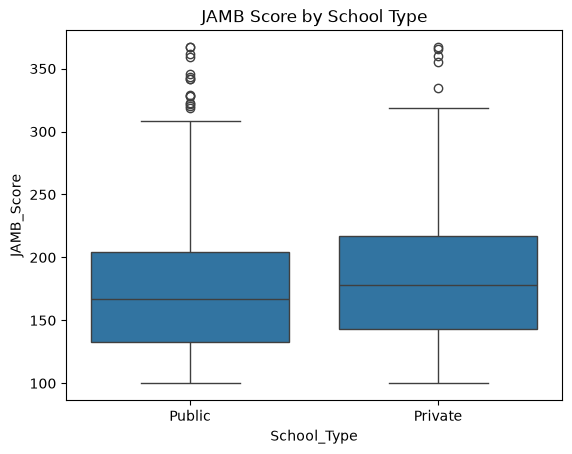

In [23]:
sns.boxplot(data=df, x='School_Type', y='JAMB_Score')
plt.title('JAMB Score by School Type')
plt.show()

In [24]:
df.groupby(['Socioeconomic_Status', 'School_Type'])['JAMB_Score'].mean()

Socioeconomic_Status  School_Type
High                  Private        198.598616
                      Public         187.882724
Low                   Private        168.023669
                      Public         163.630886
Medium                Private        184.767591
                      Public         170.801068
Name: JAMB_Score, dtype: float64

Question: Do private school students score differently from public school students?

Finding:
* School type: Private school students scored higher than public school students (181.2 vs 171.7). The gap held within every income group (about 4 to 14 points), so it is not explained by income alone.

* Income: Socioeconomic status showed the largest gaps. High-income students scored about 24 to 31 points above low-income students in the same type of school


Caution: This doesn’t prove private schools teach better. Private school students may still differ in other ways, such as study hours, learning materials or tutorials.

In [22]:
df.groupby('School_Location')['JAMB_Score'].agg(['mean', 'median', 'count'])

,mean,median,count
School_Location,,,
Rural,172.549861,169.0,2166
Urban,175.239944,170.5,2834


Location: Urban and rural students scored almost the same (175.2 vs 172.5), so location had little link to scores.

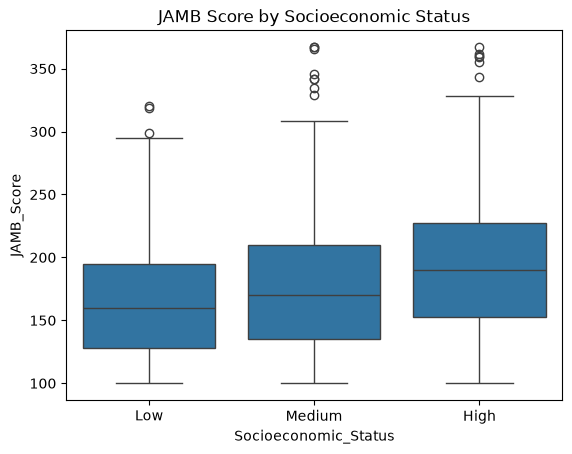

,mean,median,count
Socioeconomic_Status,,,
High,190.744917,190.0,1082
Low,164.772424,160.0,1951
Medium,174.131164,170.0,1967


In [25]:
sns.boxplot(data=df, x='Socioeconomic_Status', y='JAMB_Score', order=['Low', 'Medium', 'High'])
plt.title('JAMB Score by Socioeconomic Status')
plt.show()

df.groupby('Socioeconomic_Status')['JAMB_Score'].agg(['mean', 'median', 'count'])

Question: Does family income relate to JAMB scores?

Finding: Yes, clearly. Average scores rose with income level: Low 164.8, Medium 174.1, High 190.7. High-income students scored about 26 points above low-income students, the largest gap among all the groups I compared.

Caution: The groups overlap heavily, so income doesn’t determine a student’s score. Also, this shows association, not cause. Income likely works through things like learning materials, school quality and study conditions.

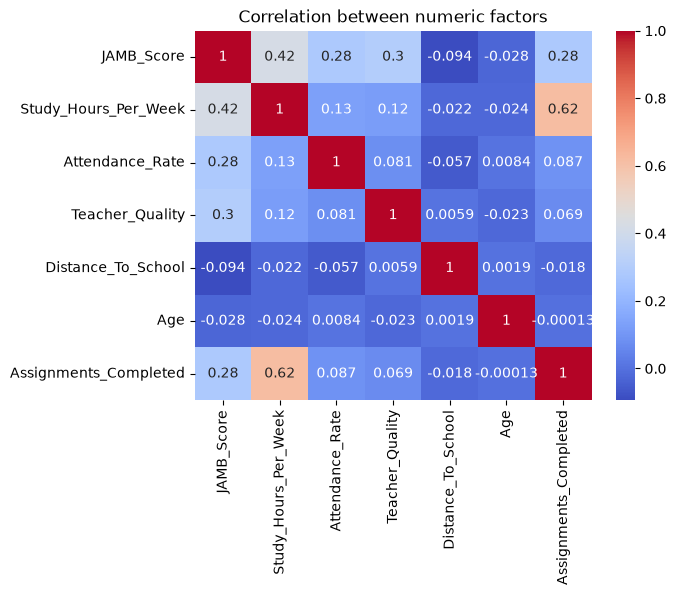

In [28]:
num_cols = df.select_dtypes('number').drop(columns=['Student_ID'])
sns.heatmap(num_cols.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation between numeric factors')
plt.show()

Question: Which numeric factors are most closely linked to JAMB score?

Finding: Study hours had the strongest link (0.42), followed by teacher quality (0.30), attendance (0.28) and assignments completed (0.28). Distance to school (-0.09) and age (-0.03) had almost no link.

Note: Study hours and assignments completed are strongly related to each other (0.62), so their effects overlap.
Caution: Correlation shows association, not cause.

Conclusion

In this dataset of 5,000 students:

Family income showed the largest gap: high-income students averaged about 26 points above low-income students (190.7 vs 164.8).
Study hours had the strongest link among numeric factors (correlation 0.42), followed by teacher quality (0.30), attendance (0.28) and assignments completed (0.28).
Private school students scored about 9.6 points higher than public school students, and the gap held at every income level.
Extra tutorials (about 6.5 points) and location (about 2.7 points) showed small or negligible differences.

Limitations: These are associations, not proof of cause. The dataset appears to be a student performance dataset and may be simulated, so these findings describe this data, not all Nigerian students.

Next steps: Test which factors still matter when considered together (for example, with a regression model).
